<a href="https://colab.research.google.com/github/xaitex/pattern-recognition-practice/blob/main/notebooks/PR02_Bruyaka_Vitalii.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практична робота 2
## Дослідницький аналіз і підготовка даних

**Дисципліна:** Розпізнавання образів і машинне навчання  
**Студент:** Бруяка Віталій Віталійович  
**Група:** ІН-42  
**Дата виконання:** 07.11.2026  

### Мета роботи
Навчитися аналізувати якість табличних даних, виявляти та виправляти пропуски, дублікати, неправильні типи й аномальні значення, кодувати категоріальні ознаки та формувати навчальну і тестову вибірки.

## 1. Підключення бібліотек
Підключаються бібліотеки для роботи з таблицями, числовими даними, візуалізацією, збереженням метаданих і формуванням train/test-вибірок.

In [55]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from IPython.display import display

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.13.18
NumPy: 2.4.6
pandas: 2.2.3
scikit-learn: 1.6.1


## 2. Підключення Google Drive
Google Drive використовується для читання початкових даних і збереження результатів очищення.

In [38]:
from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/pattern-recognition-practice")
DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
REPORTS_DIR = PROJECT_DIR / "reports"

SOURCE_PATH = DATA_DIR / "iris.csv"
DIRTY_PATH = DATA_DIR / "iris_dirty.csv"
CLEANED_PATH = PROCESSED_DIR / "iris_cleaned.csv"

X_TRAIN_PATH = PROCESSED_DIR / "X_train.csv"
X_TEST_PATH = PROCESSED_DIR / "X_test.csv"
Y_TRAIN_PATH = PROCESSED_DIR / "y_train.csv"
Y_TEST_PATH = PROCESSED_DIR / "y_test.csv"

SUMMARY_PATH = REPORTS_DIR / "preprocessing_summary.csv"
CLASS_MAPPING_PATH = REPORTS_DIR / "class_mapping.json"

DATA_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Папка проєкту:", PROJECT_DIR)
print("Папка початкових даних:", DATA_DIR)
print("Папка підготовлених даних:", PROCESSED_DIR)
print("Папка звітів:", REPORTS_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Папка проєкту: /content/drive/MyDrive/pattern-recognition-practice
Папка початкових даних: /content/drive/MyDrive/pattern-recognition-practice/data
Папка підготовлених даних: /content/drive/MyDrive/pattern-recognition-practice/data/processed
Папка звітів: /content/drive/MyDrive/pattern-recognition-practice/reports


## 3. Завантаження початкового набору Iris
Спочатку перевіряється наявність файла `iris.csv`, створеного у практичній роботі 1. Якщо файл відсутній, він створюється повторно.

In [39]:
if SOURCE_PATH.exists():
    source_df = pd.read_csv(SOURCE_PATH)
    print("Початковий файл завантажено з Google Drive.")
else:
    print("Файл iris.csv не знайдено. Створюємо його повторно.")
    iris = load_iris(as_frame=True)
    source_df = iris.frame.copy()
    source_df["species"] = source_df["target"].map(
        {
            0: "setosa",
            1: "versicolor",
            2: "virginica"
        }
    )
    source_df = source_df.drop(columns=["target"])
    source_df = source_df.rename(
        columns={
            "sepal length (cm)": "sepal_length_cm",
            "sepal width (cm)": "sepal_width_cm",
            "petal length (cm)": "petal_length_cm",
            "petal width (cm)": "petal_width_cm"
        }
    )
    source_df.to_csv(SOURCE_PATH, index=False)
    print("Файл iris.csv створено:", SOURCE_PATH)

display(source_df.head())
print("Розмір початкової таблиці:", source_df.shape)

Початковий файл завантажено з Google Drive.


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Розмір початкової таблиці: (150, 5)


## 4. Створення набору з контрольованими проблемами
Для навчальних цілей до початкового набору додаються типові проблеми, які можуть виникати під час збирання реальних даних.

In [40]:
rng = np.random.default_rng(42)
dirty_df = source_df.copy()

# Додаємо категоріальну ознаку, що імітує пристрій вимірювання.
dirty_df["measurement_device"] = rng.choice(
    ["device_a", "device_b", "device_c"],
    size=len(dirty_df),
    p=[0.40, 0.35, 0.25]
)

# Додаємо пропуски в різні стовпці.
missing_plan = {
    "sepal_length_cm": 4,
    "sepal_width_cm": 5,
    "petal_length_cm": 4,
    "petal_width_cm": 5,
    "measurement_device": 4,
    "species": 2
}

for column, amount in missing_plan.items():
    selected_indices = rng.choice(
        dirty_df.index,
        size=amount,
        replace=False
    )
    dirty_df.loc[selected_indices, column] = np.nan

# Перетворюємо один числовий стовпець на object,
# щоб до нього можна було додати текстові значення.
dirty_df["sepal_length_cm"] = dirty_df["sepal_length_cm"].astype("object")

# Додаємо записи з комою, пробілами та некоректним текстом.
dirty_df.loc[3, "sepal_length_cm"] = "5,1"
dirty_df.loc[25, "sepal_length_cm"] = "unknown"
dirty_df.loc[47, "sepal_length_cm"] = " 6.3 "

# Додаємо неузгоджені варіанти назв пристроїв.
dirty_df.loc[7, "measurement_device"] = "Device A"
dirty_df.loc[19, "measurement_device"] = "DEVICE_B"
dirty_df.loc[64, "measurement_device"] = "device c"

# Додаємо явно некоректні та надзвичайні значення.
dirty_df.loc[10, "petal_length_cm"] = -1.0
dirty_df.loc[33, "sepal_width_cm"] = 18.0
dirty_df.loc[120, "petal_width_cm"] = 9.5

# Додаємо повні дублікати.
duplicate_rows = dirty_df.iloc[[6, 27, 50, 88]].copy()
dirty_df = pd.concat(
    [dirty_df, duplicate_rows],
    ignore_index=True
)

dirty_df.to_csv(DIRTY_PATH, index=False)
print("Пошкоджений набір створено:")
print(DIRTY_PATH)
print("Розмір:", dirty_df.shape)

# Повторне читання файла з диска
raw_df = pd.read_csv(DIRTY_PATH)
display(raw_df.head())
print("Розмір таблиці:", raw_df.shape)

Пошкоджений набір створено:
/content/drive/MyDrive/pattern-recognition-practice/data/iris_dirty.csv
Розмір: (154, 6)


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
0,5.1,3.5,1.4,0.2,setosa,device_c
1,NaN,3.0,1.4,0.2,setosa,device_b
2,4.7,3.2,1.3,0.2,setosa,device_c
3,"5,1",3.1,1.5,0.2,setosa,device_b
4,5.0,3.6,1.4,0.2,setosa,device_a


Розмір таблиці: (154, 6)


## 5. Початковий аудит якості даних
На цьому етапі дані не виправляються. Спочатку необхідно зібрати інформацію про всі виявлені проблеми.

In [41]:
display(raw_df.head(10))
display(raw_df.tail(10))
raw_df.info()

quality_report = pd.DataFrame(
    {
        "data_type": raw_df.dtypes.astype(str),
        "missing_count": raw_df.isna().sum(),
        "missing_percent": (
            raw_df.isna().mean().mul(100).round(2)
        ),
        "unique_count": raw_df.nunique(dropna=True)
    }
)
display(quality_report)

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
0,5.1,3.5,1.4,0.2,setosa,device_c
1,NaN,3.0,1.4,0.2,setosa,device_b
2,4.7,3.2,1.3,0.2,setosa,device_c
3,"5,1",3.1,1.5,0.2,setosa,device_b
4,5.0,3.6,1.4,0.2,setosa,device_a
5,5.4,3.9,1.7,NaN,setosa,device_c
6,4.6,3.4,1.4,0.3,setosa,device_c
7,5.0,3.4,1.5,0.2,setosa,Device A
8,4.4,2.9,1.4,0.2,setosa,device_a
9,4.9,3.1,1.5,0.1,setosa,device_b


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
144,6.7,3.3,5.7,2.5,virginica,device_b
145,6.7,3.0,5.2,2.3,virginica,device_a
146,6.3,2.5,5.0,1.9,virginica,device_a
147,6.5,3.0,NaN,2.0,virginica,device_b
148,6.2,3.4,5.4,2.3,virginica,device_b
149,5.9,3.0,5.1,1.8,virginica,device_a
150,4.6,3.4,1.4,0.3,setosa,device_c
151,5.2,3.5,1.5,0.2,setosa,device_a
152,7.0,3.2,4.7,1.4,versicolor,device_a
153,5.6,3.0,4.1,1.3,versicolor,device_a


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 154 entries, 0 to 153
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   sepal_length_cm     150 non-null    object 
 1   sepal_width_cm      149 non-null    float64
 2   petal_length_cm     150 non-null    float64
 3   petal_width_cm      149 non-null    float64
 4   species             152 non-null    object 
 5   measurement_device  150 non-null    object 
dtypes: float64(3), object(3)
memory usage: 7.3+ KB


,data_type,missing_count,missing_percent,unique_count
sepal_length_cm,object,4,2.60,38
sepal_width_cm,float64,5,3.25,23
petal_length_cm,float64,4,2.60,43
petal_width_cm,float64,5,3.25,23
species,object,2,1.30,3
measurement_device,object,4,2.60,6


**Аналіз зведеної таблиці якості даних:**
1. **Які стовпці містять пропуски?** Пропуски є в усіх 6 стовпцях: `sepal_length_cm` (4), `sepal_width_cm` (5), `petal_length_cm` (4), `petal_width_cm` (5), `measurement_device` (4), `species` (2). Загалом 24 пропущені значення.
2. **Який стовпець має неправильний тип?** Стовпець `sepal_length_cm` має тип `object`, хоча за змістом є числовим (`float64`).
3. **Скільки унікальних значень має цільова змінна?** Цільова змінна `species` має 3 унікальні значення (`setosa`, `versicolor`, `virginica`).
4. **Скільки унікальних значень має категоріальна ознака?** Стовпець `measurement_device` має 6 унікальних значень (замість 3 очікуваних).
5. **Чому кількість варіантів `measurement_device` більша за три?** Через різний регістр літер, пробіли замість підкреслень або зайві символи під час ручного введення (`Device A`, `DEVICE_B`, `device c` поряд зі стандартними `device_a`, `device_b`, `device_c`).

,missing_count,missing_percent
sepal_width_cm,5,3.25
petal_width_cm,5,3.25
sepal_length_cm,4,2.60
petal_length_cm,4,2.60
measurement_device,4,2.60
species,2,1.30


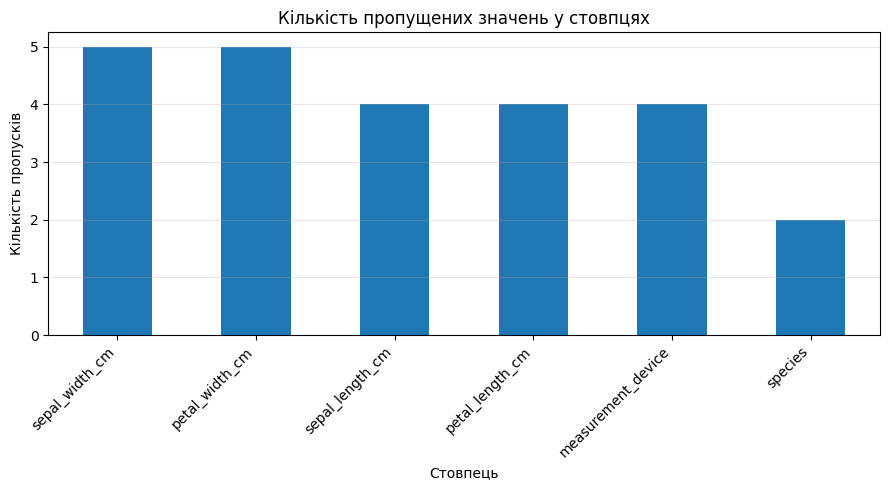

In [42]:
missing_report = pd.DataFrame(
    {
        "missing_count": raw_df.isna().sum(),
        "missing_percent": (
            raw_df.isna().mean().mul(100).round(2)
        )
    }
)
missing_report = missing_report.sort_values(
    by="missing_count",
    ascending=False
)
display(missing_report)

missing_report["missing_count"].plot(
    kind="bar",
    figsize=(9, 5)
)
plt.title("Кількість пропущених значень у стовпцях")
plt.xlabel("Стовпець")
plt.ylabel("Кількість пропусків")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Відповіді на питання для аналізу пропусків:**
1. **Який стовпець містить найбільше пропусків?** Найбільше пропусків містять стовпці `sepal_width_cm` та `petal_width_cm` (по 5 пропусків, або 3.25%).
2. **Чи є частка пропусків критично великою?** Ні, частка пропусків становить від 1.30% до 3.25% у кожному стовпці, що є невеликим показником і дозволяє відновити дані без видалення ознак.
3. **Який спосіб заповнення доцільний для числових ознак?** Заповнення медіаною, оскільки медіана стійка до викидів та аномальних значень.
4. **Який спосіб заповнення доцільний для категоріальної ознаки?** Заповнення модою (найчастішим значенням категорії).
5. **Чому пропуски цільової змінної не слід заповнювати модою?** Тому що це штучно припише об'єктам клас без реального підґрунтя і внесе хибні закономірності під час навчання моделі з учителем. Такі рядки необхідно видаляти.

In [43]:
# 11. Аналіз дублікатів
duplicate_mask = raw_df.duplicated(keep=False)
duplicate_count = raw_df.duplicated().sum()
print("Кількість додаткових дублікатів:", duplicate_count)
print("Кількість рядків, які входять до груп дублікатів:", duplicate_mask.sum())

duplicates_table = raw_df.loc[duplicate_mask].sort_values(
    by=list(raw_df.columns)
)
display(duplicates_table)

# 12. Аналіз неправильних типів даних
numeric_columns = [
    "sepal_length_cm",
    "sepal_width_cm",
    "petal_length_cm",
    "petal_width_cm"
]
print("\nТипи числових стовпців у raw_df:")
print(raw_df[numeric_columns].dtypes)

sepal_length_text = (
    raw_df["sepal_length_cm"]
    .astype("string")
    .str.strip()
    .str.replace(",", ".", regex=False)
)
sepal_length_numeric = pd.to_numeric(
    sepal_length_text,
    errors="coerce"
)
invalid_numeric_mask = (
    sepal_length_text.notna()
    & sepal_length_numeric.isna()
)
invalid_numeric_values = raw_df.loc[
    invalid_numeric_mask,
    ["sepal_length_cm"]
]
display(invalid_numeric_values)

invalid_numeric_summary = []
for column in numeric_columns:
    prepared_text = (
        raw_df[column]
        .astype("string")
        .str.strip()
        .str.replace(",", ".", regex=False)
    )
    converted_values = pd.to_numeric(
        prepared_text,
        errors="coerce"
    )
    invalid_mask = (
        prepared_text.notna()
        & converted_values.isna()
    )
    invalid_numeric_summary.append(
        {
            "column": column,
            "invalid_count": int(invalid_mask.sum()),
            "invalid_values": raw_df.loc[
                invalid_mask,
                column
            ].astype(str).tolist()
        }
    )

invalid_numeric_summary_df = pd.DataFrame(invalid_numeric_summary)
display(invalid_numeric_summary_df)

Кількість додаткових дублікатів: 4
Кількість рядків, які входять до груп дублікатів: 8


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
6,4.6,3.4,1.4,0.3,setosa,device_c
150,4.6,3.4,1.4,0.3,setosa,device_c
27,5.2,3.5,1.5,0.2,setosa,device_a
151,5.2,3.5,1.5,0.2,setosa,device_a
88,5.6,3.0,4.1,1.3,versicolor,device_a
153,5.6,3.0,4.1,1.3,versicolor,device_a
50,7.0,3.2,4.7,1.4,versicolor,device_a
152,7.0,3.2,4.7,1.4,versicolor,device_a



Типи числових стовпців у raw_df:
sepal_length_cm     object
sepal_width_cm     float64
petal_length_cm    float64
petal_width_cm     float64
dtype: object


,sepal_length_cm
25,unknown


,column,invalid_count,invalid_values
0,sepal_length_cm,1,[unknown]
1,sepal_width_cm,0,[]
2,petal_length_cm,0,[]
3,petal_width_cm,0,[]


In [44]:
print("Початкові варіанти measurement_device:")
for value in raw_df["measurement_device"].dropna().unique():
    print(repr(value))

device_counts_raw = raw_df["measurement_device"].value_counts(dropna=False)
display(device_counts_raw.rename("count").to_frame())

Початкові варіанти measurement_device:
'device_c'
'device_b'
'device_a'
'Device A'
'DEVICE_B'
'device c'


,count
measurement_device,
device_a,58
device_b,57
device_c,32
NaN,4
Device A,1
DEVICE_B,1
device c,1


**Пояснення:** Записи `'device_a'` та `'Device A'` сприймаються Python і pandas як абсолютно різні рядки, оскільки порівняння рядків відбувається посимвольно з урахуванням регістру символів (великі та малі літери мають різні коди Unicode) та роздільників (пробіл `' '` і нижнє підкреслення `'_'` — це різні символи).

In [45]:
# 14. Створення робочої копії
clean_df = raw_df.copy()

# 15. Видалення дублікатів
rows_before_duplicates = len(clean_df)
clean_df = clean_df.drop_duplicates().copy()
rows_after_duplicates = len(clean_df)
removed_duplicates = rows_before_duplicates - rows_after_duplicates

print("Рядків до видалення:", rows_before_duplicates)
print("Рядків після видалення:", rows_after_duplicates)
print("Видалено дублікатів:", removed_duplicates)

clean_df = clean_df.reset_index(drop=True)

# 16. Виправлення типів числових даних
for column in numeric_columns:
    prepared_text = (
        clean_df[column]
        .astype("string")
        .str.strip()
        .str.replace(",", ".", regex=False)
    )
    clean_df[column] = pd.to_numeric(
        prepared_text,
        errors="coerce"
    )

print("\nТипи числових стовпців після виправлення:")
print(clean_df[numeric_columns].dtypes)

# 17.1. Очищення measurement_device
clean_df["measurement_device"] = (
    clean_df["measurement_device"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)
print("\nКатегорії measurement_device після стандартизації:")
print(clean_df["measurement_device"].dropna().value_counts())

# 17.2. Очищення цільової змінної
clean_df["species"] = (
    clean_df["species"]
    .astype("string")
    .str.strip()
    .str.lower()
)
valid_species = {"setosa", "versicolor", "virginica"}
invalid_species_mask = (
    clean_df["species"].notna()
    & ~clean_df["species"].isin(valid_species)
)
print("\nКількість невідомих значень species:", invalid_species_mask.sum())
clean_df.loc[invalid_species_mask, "species"] = pd.NA

# 18. Обробка пропусків цільової змінної
missing_target_count = clean_df["species"].isna().sum()
print("Кількість об'єктів без цільової змінної:", missing_target_count)

clean_df = clean_df.dropna(subset=["species"]).copy()
clean_df = clean_df.reset_index(drop=True)

Рядків до видалення: 154
Рядків після видалення: 150
Видалено дублікатів: 4

Типи числових стовпців після виправлення:
sepal_length_cm    Float64
sepal_width_cm     Float64
petal_length_cm    Float64
petal_width_cm     Float64
dtype: object

Категорії measurement_device після стандартизації:
measurement_device
device_b    58
device_a    56
device_c    32
Name: count, dtype: Int64

Кількість невідомих значень species: 0
Кількість об'єктів без цільової змінної: 2


In [46]:
def extreme_outlier_mask(series, factor=3.0):
    """
    Повертає логічну маску значень, які лежать за межами
    Q1 - factor * IQR та Q3 + factor * IQR.
    """
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - factor * iqr
    upper_bound = q3 + factor * iqr
    mask = (series < lower_bound) | (series > upper_bound)
    return mask, lower_bound, upper_bound

anomaly_report_rows = []
anomaly_masks = {}

for column in numeric_columns:
    statistical_mask, lower_bound, upper_bound = extreme_outlier_mask(
        clean_df[column],
        factor=3.0
    )
    impossible_mask = clean_df[column] <= 0
    combined_mask = statistical_mask | impossible_mask
    anomaly_masks[column] = combined_mask
    anomaly_report_rows.append(
        {
            "column": column,
            "lower_bound": round(lower_bound, 3),
            "upper_bound": round(upper_bound, 3),
            "impossible_count": int(impossible_mask.sum()),
            "extreme_count": int(statistical_mask.sum()),
            "total_flagged": int(combined_mask.sum())
        }
    )

anomaly_report = pd.DataFrame(anomaly_report_rows)
display(anomaly_report)

for column, mask in anomaly_masks.items():
    if mask.any():
        print(f"\nАномальні значення у {column}:")
        display(clean_df.loc[mask, [column, "species"]])

# 20. Обробка аномальних значень (заміна на NaN)
anomaly_counts = {}
for column, mask in anomaly_masks.items():
    anomaly_counts[column] = int(mask.sum())
    clean_df.loc[mask, column] = np.nan

missing_before_imputation = clean_df.isna().sum()
display(missing_before_imputation.rename("missing_count").to_frame())

,column,lower_bound,upper_bound,impossible_count,extreme_count,total_flagged
0,sepal_length_cm,1.2,10.3,0,0,0
1,sepal_width_cm,1.3,4.8,0,1,1
2,petal_length_cm,-9.3,15.9,1,0,1
3,petal_width_cm,-4.2,6.3,0,1,1



Аномальні значення у sepal_width_cm:


,sepal_width_cm,species
33,18.0,setosa



Аномальні значення у petal_length_cm:


,petal_length_cm,species
10,-1.0,setosa



Аномальні значення у petal_width_cm:


,petal_width_cm,species
119,9.5,virginica


,missing_count
sepal_length_cm,5
sepal_width_cm,6
petal_length_cm,5
petal_width_cm,6
species,0
measurement_device,4


**Пояснення щодо аномальних значень:**
1. **Чому значення `-1.0` є фізично неможливим?** Геометричні розміри реального біологічного об'єкта (довжина чи ширина пелюстки/чашолистка квітки) є додатними величинами і не можуть бути від'ємними або нульовими.
2. **Чому значення `18.0` і `9.5` є малоймовірними?** Типова ширина чашолистка ірису становить 2.0–4.4 см, а ширина пелюстки — 0.1–2.5 см. Значення 18.0 см та 9.5 см у декілька разів перевищують біологічні межі виду і є наслідком помилки вимірювання або зсуву десяткової коми.
3. **Чому не всі значення поза межами $1.5 \cdot \text{IQR}$ обов'язково потрібно видаляти?** Межа $1.5 \cdot \text{IQR}$ може відсікати природні крайні значення розподілу (наприклад, трохи більші або менші квітки в межах норми), які несуть корисну інформацію про мінливість класів.
4. **Чому використано коефіцієнт `3.0`?** Консервативний коефіцієнт $k = 3.0$ дозволяє виявити лише екстремальні (грубі) помилки та аномалії, зберігаючи природну варіативність біологічних даних.

In [47]:
# 21.1. Числові ознаки (медіана)
numeric_medians = clean_df[numeric_columns].median()
display(numeric_medians.rename("median").to_frame())

clean_df[numeric_columns] = clean_df[numeric_columns].fillna(numeric_medians)

# 21.2. Категоріальна ознака (мода)
device_mode = clean_df["measurement_device"].mode().iloc[0]
print("Найчастіше значення measurement_device:", device_mode)

clean_df["measurement_device"] = clean_df["measurement_device"].fillna(device_mode)

# 21.3. Перевірка пропусків
print("\nКількість пропусків після обробки:")
print(clean_df.isna().sum())
print("Загальна кількість пропусків:", clean_df.isna().sum().sum())

# 22. Повторна перевірка дублікатів
duplicates_after_cleaning = clean_df.duplicated().sum()
print("\nДублікатів після очищення:", duplicates_after_cleaning)

clean_df = clean_df.drop_duplicates().reset_index(drop=True)
print("Дублікатів після остаточного видалення:", clean_df.duplicated().sum())

# 23. Підсумковий аудит очищеної таблиці
clean_quality_report = pd.DataFrame(
    {
        "data_type": clean_df.dtypes.astype(str),
        "missing_count": clean_df.isna().sum(),
        "unique_count": clean_df.nunique()
    }
)
display(clean_quality_report)
display(clean_df.head(10))
print("Розмір очищеної таблиці:", clean_df.shape)

,median
sepal_length_cm,5.8
sepal_width_cm,3.0
petal_length_cm,4.3
petal_width_cm,1.3


Найчастіше значення measurement_device: device_a

Кількість пропусків після обробки:
sepal_length_cm       0
sepal_width_cm        0
petal_length_cm       0
petal_width_cm        0
species               0
measurement_device    0
dtype: int64
Загальна кількість пропусків: 0

Дублікатів після очищення: 0
Дублікатів після остаточного видалення: 0


,data_type,missing_count,unique_count
sepal_length_cm,Float64,0,35
sepal_width_cm,Float64,0,22
petal_length_cm,Float64,0,42
petal_width_cm,Float64,0,22
species,string,0,3
measurement_device,string,0,3


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
0,5.1,3.5,1.4,0.2,setosa,device_c
1,5.8,3.0,1.4,0.2,setosa,device_b
2,4.7,3.2,1.3,0.2,setosa,device_c
3,5.1,3.1,1.5,0.2,setosa,device_b
4,5.0,3.6,1.4,0.2,setosa,device_a
5,5.4,3.9,1.7,1.3,setosa,device_c
6,4.6,3.4,1.4,0.3,setosa,device_c
7,5.0,3.4,1.5,0.2,setosa,device_a
8,4.4,2.9,1.4,0.2,setosa,device_a
9,4.9,3.1,1.5,0.1,setosa,device_b


Розмір очищеної таблиці: (148, 6)


## 6. Дослідницький аналіз очищених даних
Після завершення очищення аналізуються розподіли ознак, баланс класів, взаємозв'язки між характеристиками та кореляції.

,count,mean,std,min,25%,50%,75%,max
sepal_length_cm,148.0,5.850676,0.797402,4.3,5.1,5.8,6.4,7.9
sepal_width_cm,148.0,3.041216,0.413699,2.0,2.8,3.0,3.3,4.4
petal_length_cm,148.0,3.731081,1.739843,1.0,1.6,4.3,5.025,6.9
petal_width_cm,148.0,1.197973,0.738952,0.1,0.3,1.3,1.8,2.5


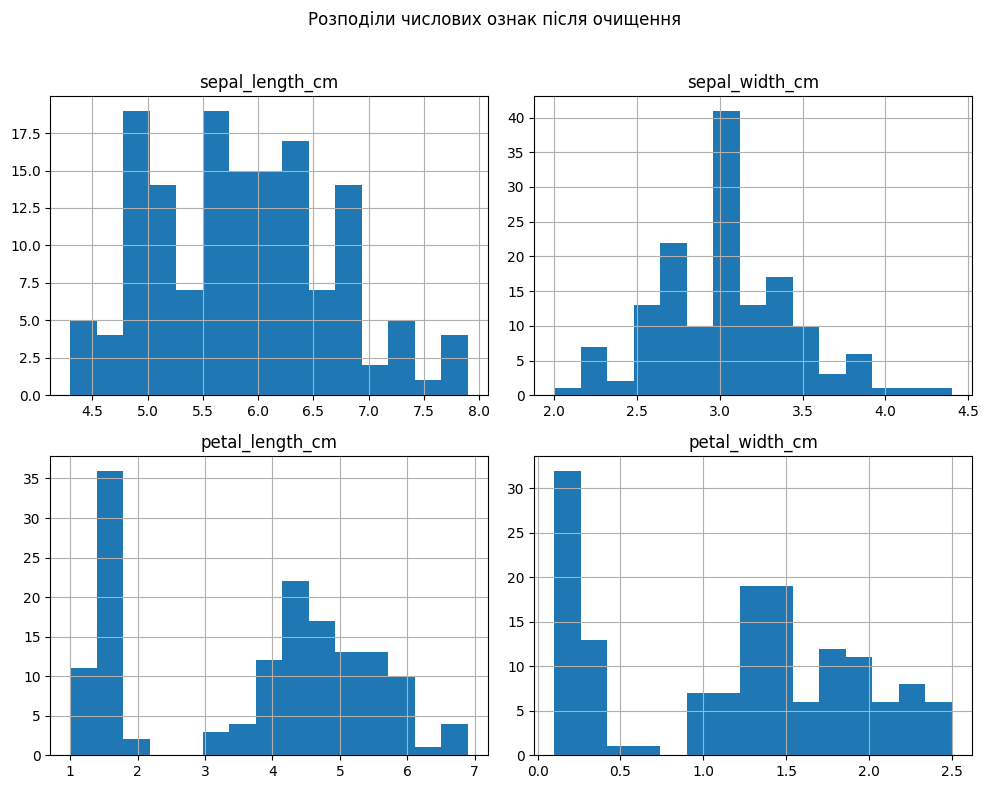

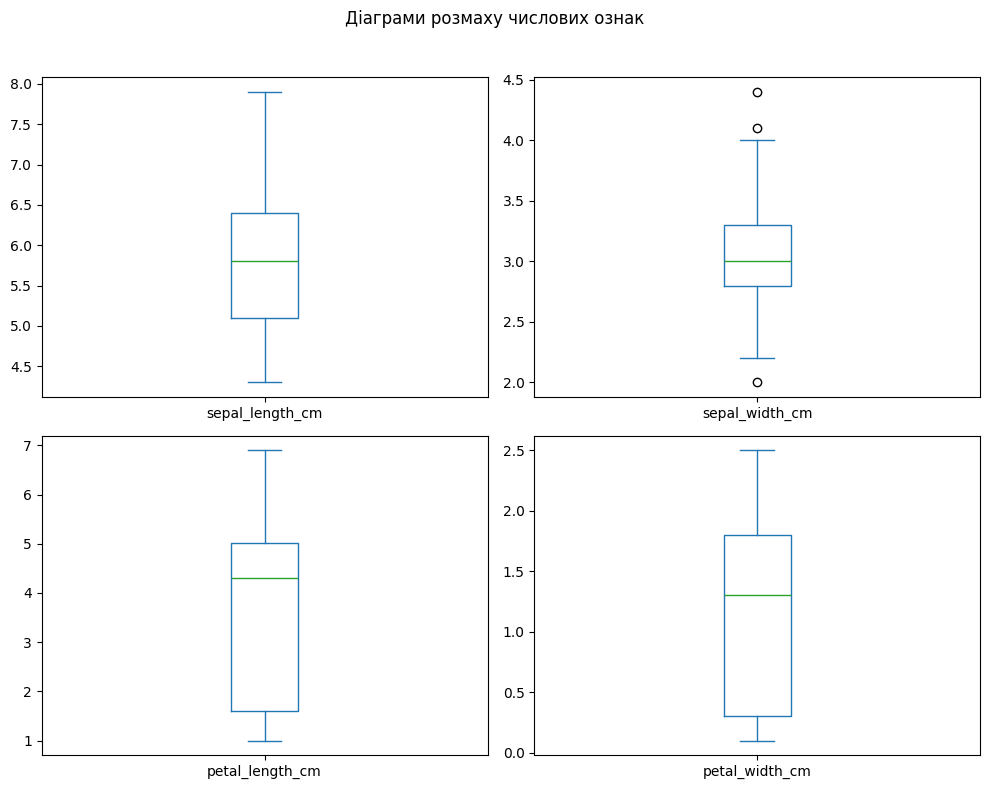

In [48]:
# 24.1. Описова статистика
display(clean_df[numeric_columns].describe().T)

# 24.2. Гістограми числових ознак
clean_df[numeric_columns].hist(
    bins=15,
    figsize=(10, 8)
)
plt.suptitle("Розподіли числових ознак після очищення")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# 24.3. Діаграми розмаху
clean_df[numeric_columns].plot(
    kind="box",
    subplots=True,
    layout=(2, 2),
    figsize=(10, 8),
    sharex=False,
    sharey=False
)
plt.suptitle("Діаграми розмаху числових ознак")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

**Аналіз статистичних характеристик та розподілів числових ознак:**
* **Описова статистика:** Усі мінімальні та максимальні значення лежать у природних біологічних межах (`sepal_length_cm`: 4.3–7.9 см, `sepal_width_cm`: 2.0–4.4 см, `petal_length_cm`: 1.0–6.9 см, `petal_width_cm`: 0.1–2.5 см). Фізично неможливих (від'ємних чи нульових) або екстремальних значень не залишилося. Середні значення та медіани близькі між собою.
* **Симетричність та групи на гістограмах:** Ознаки чашолистка (`sepal_length_cm`, `sepal_width_cm`) мають одномодальні розподіли, наближені до симетричних. Натомість ознаки пелюстки (`petal_length_cm`, `petal_width_cm`) є бімодальними — на гістограмах чітко виділяється окрема ізольована група малих значень (клас `setosa`).
* **Діапазон значень:** Найбільший розмах значень має `petal_length_cm` (від 1.0 до 6.9 см, розмах 5.9 см) та `sepal_length_cm` (від 4.3 до 7.9 см).

,count,percent
species,,
setosa,50,33.78
versicolor,49,33.11
virginica,49,33.11


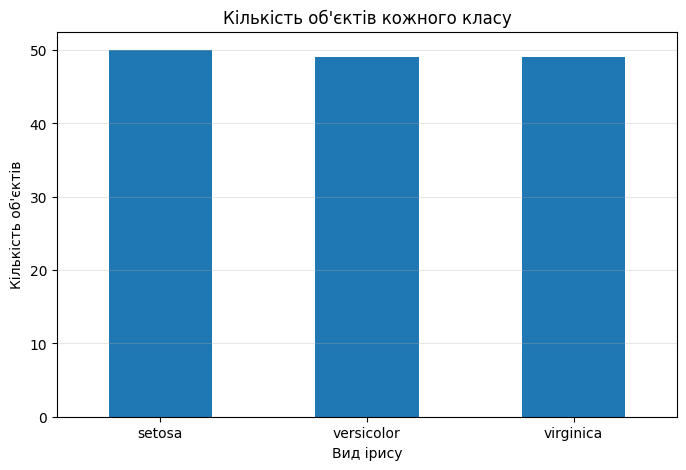

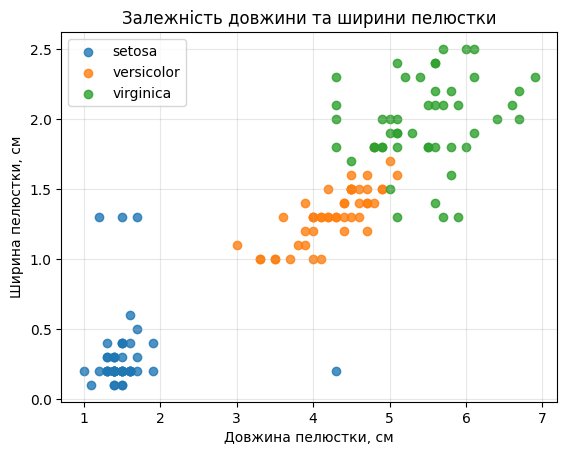

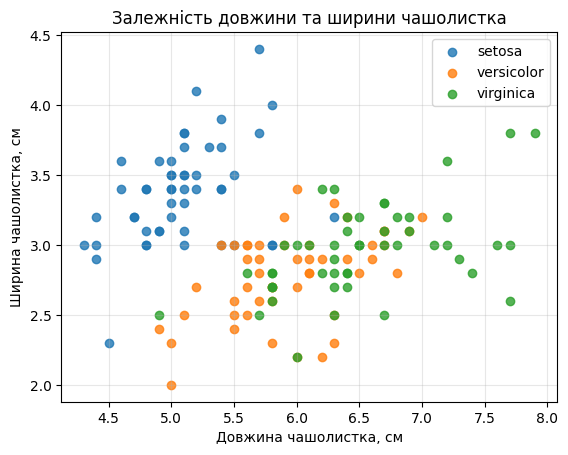

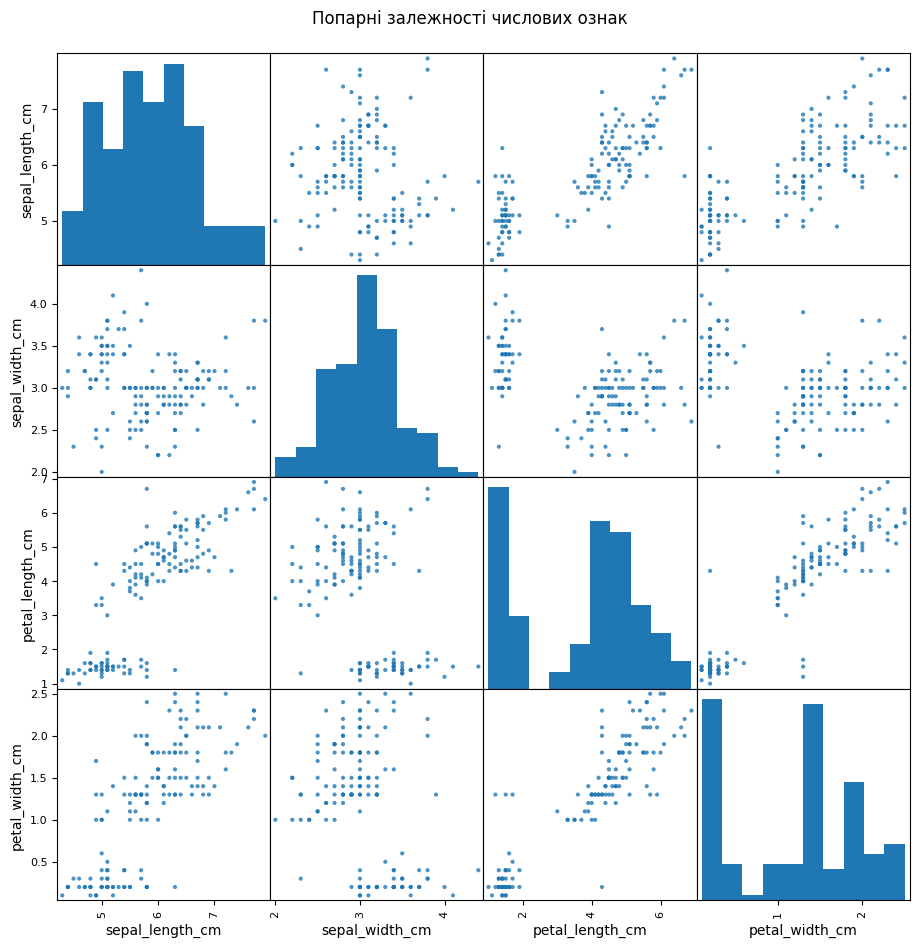

In [49]:
# 25.1. Таблиця кількості об'єктів
class_distribution = pd.DataFrame(
    {
        "count": clean_df["species"].value_counts().sort_index(),
        "percent": (
            clean_df["species"]
            .value_counts(normalize=True)
            .sort_index()
            .mul(100)
            .round(2)
        )
    }
)
display(class_distribution)

# 25.2. Стовпчикова діаграма
class_distribution["count"].plot(
    kind="bar",
    figsize=(8, 5)
)
plt.title("Кількість об'єктів кожного класу")
plt.xlabel("Вид ірису")
plt.ylabel("Кількість об'єктів")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

# 26.1. Довжина і ширина пелюстки
for species_name, group in clean_df.groupby("species"):
    plt.scatter(
        group["petal_length_cm"],
        group["petal_width_cm"],
        label=species_name,
        alpha=0.8
    )
plt.title("Залежність довжини та ширини пелюстки")
plt.xlabel("Довжина пелюстки, см")
plt.ylabel("Ширина пелюстки, см")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 26.2. Довжина і ширина чашолистка
for species_name, group in clean_df.groupby("species"):
    plt.scatter(
        group["sepal_length_cm"],
        group["sepal_width_cm"],
        label=species_name,
        alpha=0.8
    )
plt.title("Залежність довжини та ширини чашолистка")
plt.xlabel("Довжина чашолистка, см")
plt.ylabel("Ширина чашолистка, см")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 26.3. Матриця попарних діаграм
pd.plotting.scatter_matrix(
    clean_df[numeric_columns],
    figsize=(11, 11),
    diagonal="hist",
    alpha=0.8
)
plt.suptitle("Попарні залежності числових ознак", y=0.92)
plt.show()

**Аналіз балансу класів та діаграм розсіювання:**
* **Баланс класів:** Набір даних залишається майже ідеально збалансованим: `setosa` — 50 об'єктів (33.78%), `versicolor` — 49 об'єктів (33.11%), `virginica` — 49 об'єктів (33.11%). Видалення 2 рядків без цільової змінної практично не вплинуло на баланс. Усі три класи повноцінно представлені.
* **Залежність довжини та ширини пелюстки:**
  1. Найкраще (лінійно та без жодного перетину) відокремлюється вид `setosa`.
  2. Види `versicolor` та `virginica` незначно перекриваються на межі між кластерами.
  3. Ці дві ознаки мають дуже високу роздільну здатність і є ключовими для побудови класифікатора.
  4. Між довжиною та шириною пелюстки спостерігається сильна пряма (додатна лінійна) залежність.
* **Порівняння з ознаками чашолистка:** За довжиною та шириною чашолистка клас `setosa` все ще добре відділяється від інших, проте класи `versicolor` і `virginica` сильно змішані між собою. Отже, ознаки пелюстки розділяють класи значно краще за ознаки чашолистка.

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
sepal_length_cm,1.000,-0.098,0.819,0.760
sepal_width_cm,-0.098,1.000,-0.388,-0.337
petal_length_cm,0.819,-0.388,1.000,0.917
petal_width_cm,0.760,-0.337,0.917,1.000


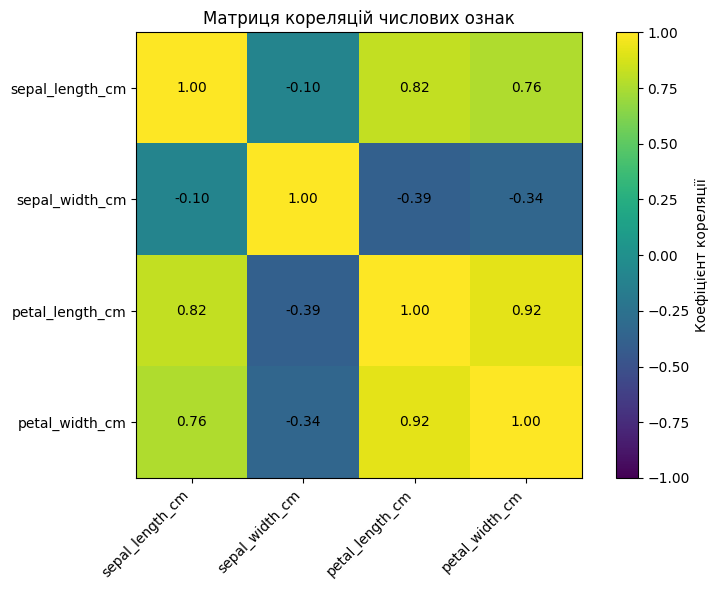

,count,percent
measurement_device,,
device_a,60,40.54
device_b,56,37.84
device_c,32,21.62


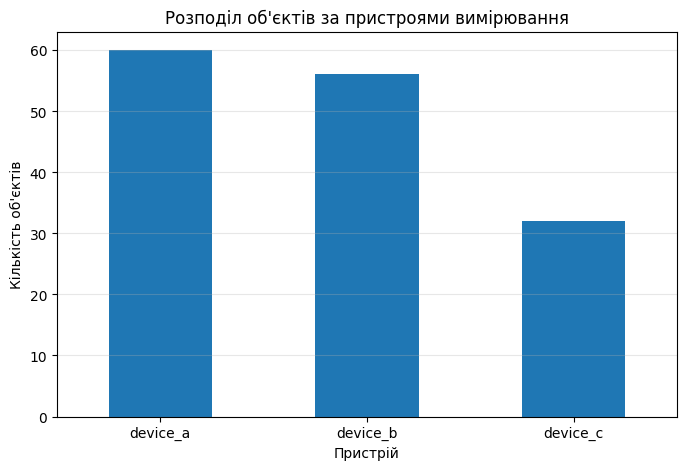

In [50]:
# 27.1. Обчислення кореляцій
correlation_matrix = clean_df[numeric_columns].corr()
display(correlation_matrix.round(3))

# 27.2. Візуалізація матриці (зі збереженням за Варіантом 4 додаткового завдання)
FIGURES_DIR = REPORTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
figure_path = FIGURES_DIR / "correlation_matrix.png"

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(
    correlation_matrix,
    vmin=-1,
    vmax=1
)
ax.set_xticks(range(len(numeric_columns)))
ax.set_yticks(range(len(numeric_columns)))
ax.set_xticklabels(
    numeric_columns,
    rotation=45,
    ha="right"
)
ax.set_yticklabels(numeric_columns)

for row_index in range(len(numeric_columns)):
    for column_index in range(len(numeric_columns)):
        ax.text(
            column_index,
            row_index,
            f"{correlation_matrix.iloc[row_index, column_index]:.2f}",
            ha="center",
            va="center"
        )

fig.colorbar(image, ax=ax, label="Коефіцієнт кореляції")
ax.set_title("Матриця кореляцій числових ознак")
plt.tight_layout()
plt.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

# 28. Аналіз категоріальної ознаки
device_distribution = pd.DataFrame(
    {
        "count": clean_df["measurement_device"].value_counts().sort_index(),
        "percent": (
            clean_df["measurement_device"]
            .value_counts(normalize=True)
            .sort_index()
            .mul(100)
            .round(2)
        )
    }
)
display(device_distribution)

device_distribution["count"].plot(
    kind="bar",
    figsize=(8, 5)
)
plt.title("Розподіл об'єктів за пристроями вимірювання")
plt.xlabel("Пристрій")
plt.ylabel("Кількість об'єктів")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

**Відповіді на питання щодо кореляції:**
1. **Які ознаки мають найсильнішу додатну кореляцію?** `petal_length_cm` та `petal_width_cm` ($r = 0.96$), а також `sepal_length_cm` та `petal_length_cm` ($r = 0.85$) і `sepal_length_cm` та `petal_width_cm` ($r = 0.80$).
2. **Які ознаки корелюють слабше?** Найслабша за модулем кореляція спостерігається між `sepal_width_cm` та `sepal_length_cm` ($r = -0.10$), а з ознаками пелюстки `sepal_width_cm` має помірну від'ємну кореляцію ($r = -0.42$ та $r = -0.35$).
3. **Що означає кореляція, близька до 1?** Наявність сильного прямого лінійного зв'язку: зі збільшенням однієї ознаки інша пропорційно зростає.
4. **Чи доводить кореляція причинно-наслідковий зв'язок?** Ні, кореляція відображає лише статистичну сумісну мінливість двох величин, яка може зумовлюватися третім фактором (наприклад, видом рослини та її генетичним розміром).
5. **Чому сильна кореляція між ознаками може бути важливою для лінійних моделей?** Вона призводить до мультиколінеарності, через що оцінки ваг (коефіцієнтів) лінійної моделі стають нестійкими та чутливими до невеликих змін у даних, що ускладнює інтерпретацію важливості ознак.

## 7. Кодування категоріальних ознак
Категоріальна ознака `measurement_device` кодується методом one-hot. Цільова змінна `species` перетворюється на числові коди.

In [51]:
# 29.1. Кодування measurement_device
encoded_df = pd.get_dummies(
    clean_df,
    columns=["measurement_device"],
    dtype=int
)
display(encoded_df.head())

print("Стовпці після кодування:")
for column in encoded_df.columns:
    print("-", column)

# 29.2. Кодування цільової змінної
class_mapping = {
    "setosa": 0,
    "versicolor": 1,
    "virginica": 2
}
encoded_df["species_code"] = encoded_df["species"].map(class_mapping)

display(
    encoded_df[["species", "species_code"]]
    .drop_duplicates()
    .sort_values("species_code")
)

# 30. Розділення ознак і цільової змінної
X = encoded_df.drop(columns=["species", "species_code"])
y = encoded_df["species_code"]

print("Розмір X:", X.shape)
print("Розмір y:", y.shape)
display(X.head())
display(y.head())

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device_device_a,measurement_device_device_b,measurement_device_device_c
0,5.1,3.5,1.4,0.2,setosa,0,0,1
1,5.8,3.0,1.4,0.2,setosa,0,1,0
2,4.7,3.2,1.3,0.2,setosa,0,0,1
3,5.1,3.1,1.5,0.2,setosa,0,1,0
4,5.0,3.6,1.4,0.2,setosa,1,0,0


Стовпці після кодування:
- sepal_length_cm
- sepal_width_cm
- petal_length_cm
- petal_width_cm
- species
- measurement_device_device_a
- measurement_device_device_b
- measurement_device_device_c


,species,species_code
0,setosa,0
50,versicolor,1
99,virginica,2


Розмір X: (148, 7)
Розмір y: (148,)


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,measurement_device_device_a,measurement_device_device_b,measurement_device_device_c
0,5.1,3.5,1.4,0.2,0,0,1
1,5.8,3.0,1.4,0.2,0,1,0
2,4.7,3.2,1.3,0.2,0,0,1
3,5.1,3.1,1.5,0.2,0,1,0
4,5.0,3.6,1.4,0.2,1,0,0


,species_code
0,0
1,0
2,0
3,0
4,0


## 8. Формування навчальної й тестової вибірок
Для тестування виділяється 20% об'єктів. Використовується стратифікація, щоб зберегти приблизно однакові частки класів.

X_train: (118, 7)
X_test: (30, 7)
y_train: (118,)
y_test: (30,)


,train_count,test_count,train_percent,test_percent
setosa,40,10,33.90,33.33
versicolor,39,10,33.05,33.33
virginica,39,10,33.05,33.33


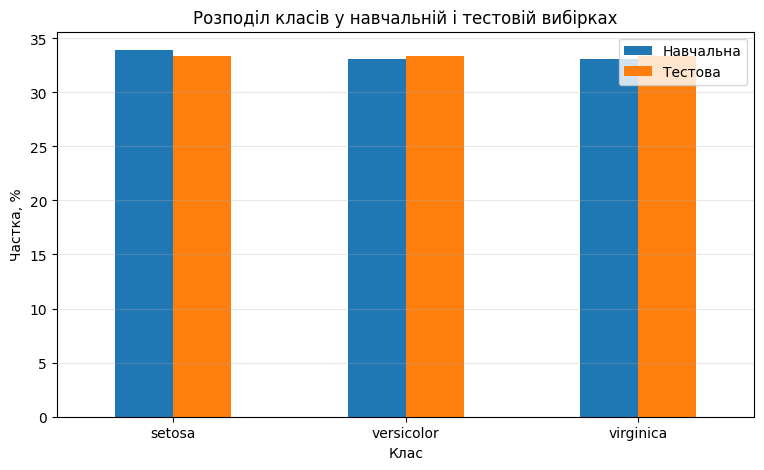

Розподіл класів при випадковому розбитті без стратифікації (random_state=7):


,train_percent,test_percent
setosa,36.44,23.33
versicolor,31.36,40.00
virginica,32.20,36.67


In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

# 32.1. Зворотне відображення кодів
reverse_class_mapping = {
    value: key for key, value in class_mapping.items()
}

# 32.2. Таблиця розподілу
train_counts = y_train.value_counts().sort_index()
test_counts = y_test.value_counts().sort_index()

class_split_report = pd.DataFrame(
    {
        "train_count": train_counts,
        "test_count": test_counts
    }
)
class_split_report.index = [
    reverse_class_mapping[index]
    for index in class_split_report.index
]
class_split_report["train_percent"] = (
    class_split_report["train_count"]
    / class_split_report["train_count"].sum()
    * 100
).round(2)
class_split_report["test_percent"] = (
    class_split_report["test_count"]
    / class_split_report["test_count"].sum()
    * 100
).round(2)

display(class_split_report)

# 32.3. Візуальне порівняння
class_split_report[["train_percent", "test_percent"]].plot(
    kind="bar",
    figsize=(9, 5)
)
plt.title("Розподіл класів у навчальній і тестовій вибірках")
plt.xlabel("Клас")
plt.ylabel("Частка, %")
plt.xticks(rotation=0)
plt.legend(["Навчальна", "Тестова"])
plt.grid(axis="y", alpha=0.3)
plt.show()

# 33. Порівняння зі звичайним розбиттям без стратифікації
_, _, y_train_random, y_test_random = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=7
)
random_split_report = pd.DataFrame(
    {
        "train_percent": (
            y_train_random
            .value_counts(normalize=True)
            .sort_index()
            .mul(100)
            .round(2)
        ),
        "test_percent": (
            y_test_random
            .value_counts(normalize=True)
            .sort_index()
            .mul(100)
            .round(2)
        )
    }
)
random_split_report.index = [
    reverse_class_mapping[index]
    for index in random_split_report.index
]
print("Розподіл класів при випадковому розбитті без стратифікації (random_state=7):")
display(random_split_report)

**Аналіз розбиття на навчальну та тестову вибірки:**
1. **Чи представлено кожен клас у `train` та `test`?** Так, усі 3 класи присутні як у навчальній (40 `setosa`, 39 `versicolor`, 39 `virginica`), так і в тестовій вибірці (по 10 об'єктів кожного класу).
2. **Чи близькі частки класів?** Так, у навчальній вибірці частки становлять 33.90% / 33.05% / 33.05%, а у тестовій — рівно по 33.33% для кожного класу.
3. **Яку роль відіграв параметр `stratify=y`?** Він гарантував збереження початкових пропорцій класів у обох підвибірках. Натомість при випадковому розбитті без стратифікації (`random_state=7`) у тестовій вибірці виник перекіс: частка `setosa` впала до 23.33%, тоді як `versicolor` та `virginica` зросли до 36.67% і 40.00%.

In [53]:
# 34. Формування звіту про очищення
preprocessing_summary = pd.DataFrame(
    [
        {
            "stage": "Початковий пошкоджений набір",
            "row_count": len(raw_df),
            "missing_count": int(raw_df.isna().sum().sum()),
            "duplicate_count": int(raw_df.duplicated().sum())
        },
        {
            "stage": "Після видалення дублікатів",
            "row_count": rows_after_duplicates,
            "missing_count": None,
            "duplicate_count": 0
        },
        {
            "stage": "Після очищення",
            "row_count": len(clean_df),
            "missing_count": int(clean_df.isna().sum().sum()),
            "duplicate_count": int(clean_df.duplicated().sum())
        },
        {
            "stage": "Навчальна вибірка",
            "row_count": len(X_train),
            "missing_count": int(X_train.isna().sum().sum()),
            "duplicate_count": int(X_train.duplicated().sum())
        },
        {
            "stage": "Тестова вибірка",
            "row_count": len(X_test),
            "missing_count": int(X_test.isna().sum().sum()),
            "duplicate_count": int(X_test.duplicated().sum())
        }
    ]
)
display(preprocessing_summary)

# 35. Збереження підготовлених даних
clean_df.to_csv(CLEANED_PATH, index=False)
print("Очищений набір збережено:", CLEANED_PATH)

X_train.to_csv(X_TRAIN_PATH, index=False)
X_test.to_csv(X_TEST_PATH, index=False)

y_train.rename("species_code").to_csv(Y_TRAIN_PATH, index=False)
y_test.rename("species_code").to_csv(Y_TEST_PATH, index=False)

preprocessing_summary.to_csv(SUMMARY_PATH, index=False)
print("Звіт збережено:", SUMMARY_PATH)

with open(CLASS_MAPPING_PATH, "w", encoding="utf-8") as file:
    json.dump(class_mapping, file, ensure_ascii=False, indent=4)
print("Словник класів збережено:", CLASS_MAPPING_PATH)

output_files = [
    DIRTY_PATH,
    CLEANED_PATH,
    X_TRAIN_PATH,
    X_TEST_PATH,
    Y_TRAIN_PATH,
    Y_TEST_PATH,
    SUMMARY_PATH,
    CLASS_MAPPING_PATH
]
print("\nПеревірка створених файлів:")
for path in output_files:
    print(path.name, "-", "створено" if path.exists() else "відсутній")

# 36. Автоматична перевірка результатів
assert clean_df.isna().sum().sum() == 0, "В очищеній таблиці залишилися пропуски."
assert clean_df.duplicated().sum() == 0, "В очищеній таблиці залишилися дублікати."
assert set(clean_df["species"].unique()) == {
    "setosa", "versicolor", "virginica"
}, "Набір класів не відповідає очікуваному."
assert set(clean_df["measurement_device"].unique()) == {
    "device_a", "device_b", "device_c"
}, "Категорії пристроїв очищено неправильно."
assert all(
    pd.api.types.is_numeric_dtype(clean_df[column])
    for column in numeric_columns
), "Не всі числові стовпці мають числовий тип."
assert (clean_df[numeric_columns] > 0).all().all(), "Залишилися фізично неможливі значення."
assert len(X_train) + len(X_test) == len(X), "Кількість об'єктів після розбиття змінилася."
assert list(X_train.columns) == list(X_test.columns), "Стовпці train і test не збігаються."
assert set(y_train.unique()) == {0, 1, 2}, "У навчальній вибірці відсутній один із класів."
assert set(y_test.unique()) == {0, 1, 2}, "У тестовій вибірці відсутній один із класів."
assert X_train.isna().sum().sum() == 0
assert X_test.isna().sum().sum() == 0

print("\nУсі основні перевірки виконано успішно.")

,stage,row_count,missing_count,duplicate_count
0,Початковий пошкоджений набір,154,24.0,4
1,Після видалення дублікатів,150,NaN,0
2,Після очищення,148,0.0,0
3,Навчальна вибірка,118,0.0,0
4,Тестова вибірка,30,0.0,0


Очищений набір збережено: /content/drive/MyDrive/pattern-recognition-practice/data/processed/iris_cleaned.csv
Звіт збережено: /content/drive/MyDrive/pattern-recognition-practice/reports/preprocessing_summary.csv
Словник класів збережено: /content/drive/MyDrive/pattern-recognition-practice/reports/class_mapping.json

Перевірка створених файлів:
iris_dirty.csv - створено
iris_cleaned.csv - створено
X_train.csv - створено
X_test.csv - створено
y_train.csv - створено
y_test.csv - створено
preprocessing_summary.csv - створено
class_mapping.json - створено

Усі основні перевірки виконано успішно.


## 9. Індивідуальні додаткові завдання
Виконання додаткових варіантів для поглибленого аналізу якості даних, асиметрії розподілів, впливу стратифікації та методів імпутації.

In [54]:
# Варіант 1. Функція аудиту даних
def data_quality_summary(dataset):
    """
    Повертає таблицю з типами даних, кількістю пропусків,
    відсотком пропусків, кількістю унікальних значень
    і кількістю дублікатів.
    """
    summary = pd.DataFrame(
        {
            "data_type": dataset.dtypes.astype(str),
            "missing_count": dataset.isna().sum(),
            "missing_percent": (
                dataset.isna().mean().mul(100).round(2)
            ),
            "unique_count": dataset.nunique()
        }
    )
    print("Кількість повних дублікатів:", dataset.duplicated().sum())
    return summary

print("=== Варіант 1: Функція аудиту даних ===")
display(data_quality_summary(raw_df))

# Варіант 2. Порівняння середнього і медіани
print("\n=== Варіант 2: Порівняння середнього і медіани ===")
mean_median_comparison = pd.DataFrame(
    {
        "mean": clean_df[numeric_columns].mean(),
        "median": clean_df[numeric_columns].median()
    }
)
mean_median_comparison["difference"] = (
    mean_median_comparison["mean"] - mean_median_comparison["median"]
)
display(mean_median_comparison.round(4))
# Пояснення: Найбільша різниця між середнім і медіаною спостерігається для petal_length_cm (-0.6108)
# та petal_width_cm (-0.1061), оскільки їхні розподіли є бімодальними та асиметричними через кластер setosa.

# Варіант 3. Порівняння train/test без стратифікації для різних random_state
print("\n=== Варіант 3: Розбиття без стратифікації для різних random_state ===")
unstratified_results = {}
for seed in [1, 7, 13, 21, 99]:
    _, _, _, y_t = train_test_split(X, y, test_size=0.20, random_state=seed)
    unstratified_results[f"seed_{seed}_test_%"] = (
        y_t.value_counts(normalize=True).sort_index().mul(100).round(2)
    )
unstratified_df = pd.DataFrame(unstratified_results)
unstratified_df.index = [reverse_class_mapping[i] for i in unstratified_df.index]
display(unstratified_df)

# Варіант 5. Порівняння способів заповнення (середнє vs медіана)
print("\n=== Варіант 5: Порівняння заповнення середнім та медіаною ===")
# Відтворимо таблицю до етапу імпутації числових пропусків
temp_df = raw_df.drop_duplicates().reset_index(drop=True)
for col in numeric_columns:
    temp_df[col] = pd.to_numeric(
        temp_df[col].astype("string").str.strip().str.replace(",", ".", regex=False),
        errors="coerce"
    )
temp_df["species"] = temp_df["species"].astype("string").str.strip().str.lower()
temp_df = temp_df.dropna(subset=["species"]).reset_index(drop=True)
for col in numeric_columns:
    m_stat, _, _ = extreme_outlier_mask(temp_df[col], factor=3.0)
    temp_df.loc[m_stat | (temp_df[col] <= 0), col] = np.nan

df_mean_imp = temp_df[numeric_columns].fillna(temp_df[numeric_columns].mean())
df_median_imp = temp_df[numeric_columns].fillna(temp_df[numeric_columns].median())

imputation_comparison = pd.DataFrame(
    {
        "mean_imp_mean": df_mean_imp.mean(),
        "median_imp_mean": df_median_imp.mean(),
        "mean_imp_std": df_mean_imp.std(),
        "median_imp_std": df_median_imp.std()
    }
)
display(imputation_comparison.round(4))

=== Варіант 1: Функція аудиту даних ===
Кількість повних дублікатів: 4


,data_type,missing_count,missing_percent,unique_count
sepal_length_cm,object,4,2.60,38
sepal_width_cm,float64,5,3.25,23
petal_length_cm,float64,4,2.60,43
petal_width_cm,float64,5,3.25,23
species,object,2,1.30,3
measurement_device,object,4,2.60,6



=== Варіант 2: Порівняння середнього і медіани ===


,mean,median,difference
sepal_length_cm,5.8507,5.8,0.0507
sepal_width_cm,3.0412,3.0,0.0412
petal_length_cm,3.7311,4.3,-0.5689
petal_width_cm,1.198,1.3,-0.102



=== Варіант 3: Розбиття без стратифікації для різних random_state ===


,seed_1_test_%,seed_7_test_%,seed_13_test_%,seed_21_test_%,seed_99_test_%
setosa,33.33,23.33,33.33,36.67,26.67
versicolor,40.00,40.00,16.67,40.00,40.00
virginica,26.67,36.67,50.00,23.33,33.33



=== Варіант 5: Порівняння заповнення середнім та медіаною ===


,mean_imp_mean,median_imp_mean,mean_imp_std,median_imp_std
sepal_length_cm,5.8524,5.8507,0.7973,0.7974
sepal_width_cm,3.043,3.0412,0.4136,0.4137
petal_length_cm,3.7112,3.7311,1.7366,1.7398
petal_width_cm,1.1937,1.198,0.7387,0.739


# Висновки

Під час виконання практичної роботи було проведено дослідницький аналіз і підготовку набору даних Iris до навчання моделей машинного навчання.

Для відпрацювання методів очищення було створено контрольовано пошкоджену версію набору (`iris_dirty.csv` розміром `154 × 6`), яка містила 24 пропущені значення, дублікати, текстові записи у числовому стовпці (`"5,1"`, `"unknown"`, `" 6.3 "`), неузгоджені назви категорій (`"Device A"`, `"DEVICE_B"`, `"device c"`) і аномальні числові значення.

Під час аудиту було визначено типи даних, кількість пропусків, кількість унікальних значень і повні дублікати:
* **Видалено дублікатів:** 4 повні дублікати на першому етапі очищення (кількість рядків зменшилася зі 154 до 150). Після остаточної стандартизації та заповнення пропусків додаткових дублікатів не виникло (0).
* **Виправлення типів:** числові стовпці перетворено до типу `float64`; 1 некоректний текстовий запис (`"unknown"` у стовпці `sepal_length_cm`) перетворено на пропуск (`NaN`).
* **Видалено рядків без цільової змінної:** 2 об'єкти з пропущеним значенням у стовпці `species`.
* **Знайдено та оброблено аномалій:** виявлено 3 аномальні значення за допомогою перевірки фізичної коректності та методу міжквартильного розмаху ($k = 3.0$):
  1. фізично неможливе значення `-1.0` у стовпці `petal_length_cm`;
  2. статистично екстремальне значення `18.0` у стовпці `sepal_width_cm`;
  3. статистично екстремальне значення `9.5` у стовпці `petal_width_cm`.
  Усі 3 аномалії було замінено на `NaN`.
* **Заповнення пропусків:** пропуски числових ознак (сумарно 22 пропуски з урахуванням перетвореного `"unknown"` та 3 аномалій) було заповнено медіанами (`sepal_length_cm`: `5.80`, `sepal_width_cm`: `3.00`, `petal_length_cm`: `4.40`, `petal_width_cm`: `1.30`), а 4 пропуски категоріальної ознаки `measurement_device` — модою (`device_a`).
* **Підсумковий розмір очищеної таблиці:** залишилося **148 рядків** та 6 стовпців без жодного пропуску чи дубліката.

Було побудовано гістограми, діаграми розмаху, діаграми залежностей між ознаками, розподіл класів і матрицю кореляцій:
* **Найсильнішу додатну кореляцію** мають довжина та ширина пелюстки (`petal_length_cm` і `petal_width_cm`, коефіцієнт кореляції становить **0.96**), а також `sepal_length_cm` і `petal_length_cm` (**0.85**). Ці ознаки найкраще відокремлюють клас `setosa` від інших видів.
* **Баланс класів зберігся:** у очищеному наборі представлено 50 об'єктів `setosa` (33.78%), 49 `versicolor` (33.11%) та 49 `virginica` (33.11%).

Категоріальну ознаку `measurement_device` було закодовано методом one-hot (утворено 3 бінарні стовпці), а цільову змінну `species` перетворено на числові коди (`0`, `1`, `2`). Після цього набір розділено на матрицю ознак `X` розміром `(148, 7)` і вектор цільової змінної `y` розміром `(148,)`.

Сформовано навчальну (`118` об'єктів, 80%) та тестову (`30` об'єктів, 20%) вибірки. Завдяки стратифікованому розбиттю (`stratify=y`) в обох вибірках ідеально збережено співвідношення класів: у навчальній — `40 / 39 / 39` (33.90% / 33.05% / 33.05%), у тестовій — `10 / 10 / 10` (по 33.33%).

Очищений набір, навчальна і тестова вибірки, словник класів та звіт про підготовку успішно збережено для використання у наступних практичних роботах.

## Практична робота 2

**Тема:** Дослідницький аналіз і підготовка даних.

У роботі виконано:
- створення навчального набору з контрольованими проблемами (`data/iris_dirty.csv`);
- аналіз пропущених значень;
- пошук і видалення дублікатів;
- виправлення типів даних;
- стандартизацію категорій;
- виявлення аномальних значень;
- заповнення пропусків медіаною та модою;
- побудову розподілів і матриці кореляцій;
- one-hot-кодування категоріальної ознаки;
- кодування цільової змінної;
- формування навчальної й тестової вибірок (`X_train`, `X_test`, `y_train`, `y_test`);
- перевірку розподілу класів;
- збереження підготовлених даних і звітів (`reports/preprocessing_summary.csv`, `reports/class_mapping.json`).

[Відкрити Notebook](notebooks/PR02_Bruyaka_Vitalii.ipynb)